In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Veri setini yükle
df = pd.read_csv("breast_cancer.csv")

# Veri setinin boyutu
print("Veri setinin boyutu:", df.shape)

# İlk 5 satırı görüntüle
df.head()

Veri setinin boyutu: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [20]:
# Eksik değer kontrolü
print("Eksik değer sayısı:", df.isnull().sum().sum())

# Sınıf dağılımı
print("\nSınıf dağılımı:")
print(df["diagnosis"].value_counts())

Eksik değer sayısı: 0

Sınıf dağılımı:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [21]:
# Giriş ve hedef değişkenlerini ayır
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"]

print("Giriş verisi:", X.shape)
print("Hedef değişken:", y.shape)

Giriş verisi: (569, 30)
Hedef değişken: (569,)


In [22]:
from sklearn.model_selection import train_test_split

# Veriyi %80 eğitim, %20 test olarak ayır
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim verisi:", X_train.shape)
print("Test verisi:", X_test.shape)

Eğitim verisi: (455, 30)
Test verisi: (114, 30)


In [23]:
from sklearn.naive_bayes import GaussianNB

# Modeli oluştur ve eğit
model = GaussianNB()
model.fit(X_train, y_train)

# Test verisi üzerinde tahmin yap
y_pred = model.predict(X_test)

print("İlk 10 tahmin:", y_pred[:10])
print("İlk 10 gerçek değer:", y_test.values[:10])

İlk 10 tahmin: ['B' 'M' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B']
İlk 10 gerçek değer: ['B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B']


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Performans metrikleri (M sınıfı pozitif)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="M")
recall = recall_score(y_test, y_pred, pos_label="M")
f1 = f1_score(y_test, y_pred, pos_label="M")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.9386
Precision: 1.0000
Recall   : 0.8333
F1 Score : 0.9091


Confusion Matrix:
[[72  0]
 [ 7 35]]


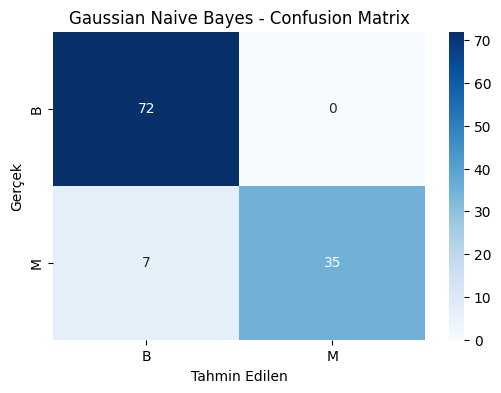

In [25]:
from sklearn.metrics import confusion_matrix

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["B", "M"])

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["B", "M"],
    yticklabels=["B", "M"]
)

plt.xlabel("Tahmin Edilen")
plt.ylabel("Gerçek")
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

In [26]:
# Duyarlılık ve özgüllük
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"Duyarlılık (Sensitivity): {sensitivity:.4f}")
print(f"Özgüllük (Specificity): {specificity:.4f}")

Duyarlılık (Sensitivity): 0.8333
Özgüllük (Specificity): 1.0000


ROC-AUC: 0.9934


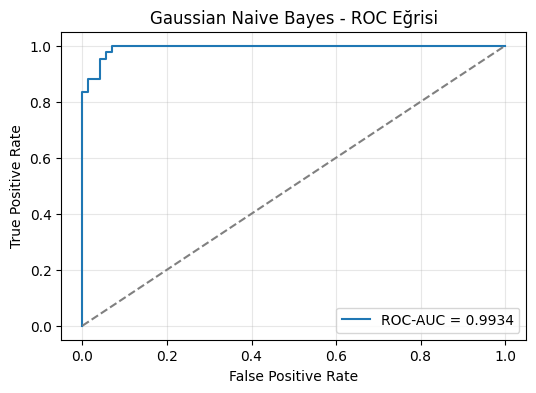

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

# M sınıfının tahmin olasılıkları
y_prob = model.predict_proba(X_test)[:, 1]

# ROC-AUC
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label="M")

print(f"ROC-AUC: {auc:.4f}")

# ROC eğrisi
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gaussian Naive Bayes - ROC Eğrisi")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Sonuç

Gaussian Naive Bayes modeli, meme kanseri veri setinde %93,86 doğruluk elde etti. Precision %100, recall %83,33, F1-score %90,91 ve ROC-AUC 0.9934 olarak hesaplandı.

Confusion Matrix sonucunda 72 iyi huylu ve 35 kötü huylu örnek doğru sınıflandırıldı. Ancak 7 kötü huylu örnek yanlışlıkla iyi huylu olarak tahmin edildi.

Modelin sınıfları ayırt etme başarısı yüksek olsa da kötü huylu örnekleri kaçırması önemli bir sınırlılıktır. Bu nedenle özellikle sağlık alanındaki sınıflandırma problemlerinde yalnızca doğruluk oranını değerlendirmek yeterli değildir.